In [38]:
import importlib
import numpy as np
import matplotlib.pyplot as plt

import nn
import plotting

importlib.reload(nn)
importlib.reload(plotting)

from nn import NeuralNetwork, train, train_classification, cross_entropy
from data import load_mnist, one_hot
from plotting import plot_heatmap, plot_confusion
from optimizers import Adam, RMSprop
from metrics import accuracy, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [39]:
(x_train, y_train), (x_val, y_val), (x_test, y_test) = load_mnist(path="../data/mnist.npz",seed=2026)
y_train_oh, y_val_oh = one_hot(y_train), one_hot(y_val) 
print(len(y_train_oh))
print(len(y_val_oh))

50000
10000


In [40]:
model = NeuralNetwork(layer_sizes=[784, 100, 10], activations=["relu", "softmax"], cost="cross_entropy", seed=2026)
optimizer = Adam(learning_rate=0.001)
history=train(model, optimizer, X=x_train, y=y_train_oh, epochs=30, batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)

In [41]:
model2 = NeuralNetwork(layer_sizes=[784, 100, 10], activations=["relu", "softmax"], cost="cross_entropy", seed=2026)
optimizer2 = RMSprop(learning_rate=0.001)
history2=train(model2, optimizer2, X=x_train, y=y_train_oh, epochs=30, batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)

In [ ]:
y_pred = model.predict(x_val)
#Adam
print(f"Validation accuracy: {accuracy(y_val, y_pred):.4f}")
print(f"Cross entropy start: {history['train'][0]:.4f}")
print(f"Cross entropy end: {history['train'][-1]:.4f}")


Validation accuracy: 0.9771
Cross entropy start: 0.2270
Cross entropy end: 0.0025


In [43]:
#Rms prop
y_pred2 = model2.predict(x_val)
print(f"Validation accuracy: {accuracy(y_val, y_pred2):.4f}")
print(f"Cross entropy start: {history2['train'][0]:.4f}")
print(f"Cross entropy end: {history2['train'][-1]:.4f}")
print(f"Training cross-entropy, siste epoch: {history2['train'][-1]:.4f}")
print(f"Lowest validation loss: {min(history2['val']):.4f}")
print(f"Best epoch: {np.argmin(history2['val']) + 1}")

Validation accuracy: 0.9768
Cross entropy start: 0.2283
Cross entropy end: 0.0030
Training cross-entropy, siste epoch: 0.0030
Lowest validation loss: 0.0939
Best epoch: 12


Lowest validation epoch at epoch:14
Lowest validation loss:0.08781866388962951


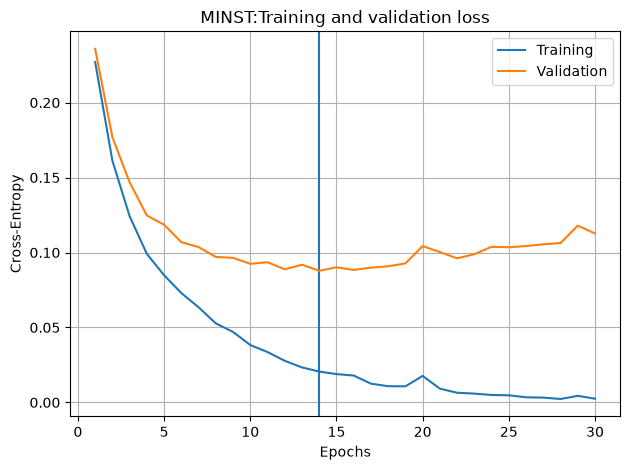

In [44]:
epochs = range(1, len(history["train"])+ 1)
best_epoch = np.argmin(history['val']) + 1
print(f'Lowest validation epoch at epoch:{best_epoch}')
print(f"Lowest validation loss:{min(history['val'])}")
plt.plot(epochs, history['train'], label = 'Training')
plt.axvline(int(best_epoch), label = '')
plt.plot(epochs, history['val'], label = 'Validation')
plt.title('MINST:Training and validation loss');plt.grid()
plt.xlabel("Epochs");plt.ylabel('Cross-Entropy');plt.legend();plt.tight_layout();plt.show()


Diffrent learning rates

In [45]:
learning_rates = [1e-4, 1e-3, 1e-2]
history_lr = {}
print(f"gamma | minimum validation loss| Best epoch| Validation accuracy")
for gamma in learning_rates:
    model_lr = NeuralNetwork(layer_sizes=[784, 100, 10], activations=["relu", "softmax"], cost="cross_entropy", seed=2026)
    optimizer_lr = Adam(learning_rate=gamma)
    history = train(model_lr, optimizer_lr, X=x_train, y=y_train_oh, epochs=30, batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)
    history_lr[gamma] = history
    best_epoch = np.argmin(history["val"]) + 1
    val_acc = np.mean(model_lr.predict(x_val)==y_val)
    print(f"{gamma:g} & {min(history['val']):.4f} & "
          f"{best_epoch} & {val_acc:.2f}" + r"\\")

gamma | minimum validation loss| Best epoch| Validation accuracy
0.0001 & 0.1413 & 30 & 0.96\\
0.001 & 0.0878 & 14 & 0.98\\
0.01 & 0.1178 & 2 & 0.97\\


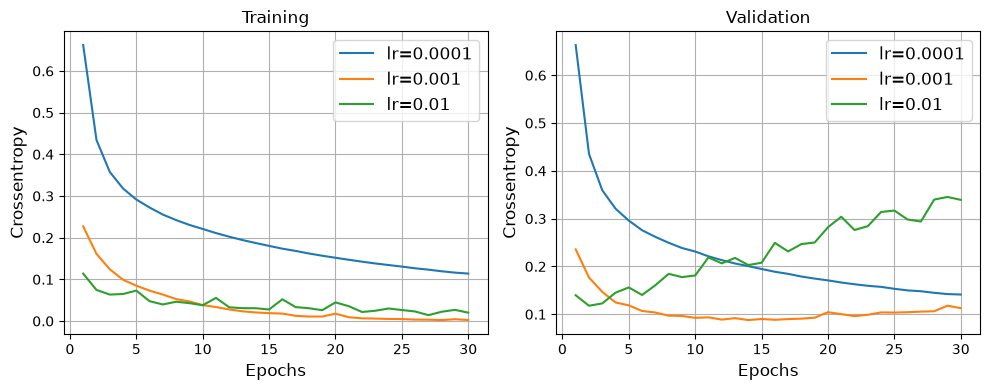

In [46]:
#Adam
fig, axes = plt.subplots(1, 2, figsize=(10,4))
for gamma, hist in history_lr.items():
    epcoh=np.arange(1, len(hist["train"])+ 1)
    axes[0].plot(epcoh, hist['train'], label = f"lr={gamma:g}")
    axes[1].plot(epcoh, hist['val'], label = f"lr={gamma:g}")
axes[0].set_title('Training', fontsize=12)
axes[1].set_title('Validation', fontsize=12)
for ax in axes:
    ax.set_xlabel('Epochs', fontsize=12)
    ax.set_ylabel('Crossentropy', fontsize=12)
    ax.legend(fontsize=12)
    ax.grid()
plt.tight_layout()
plt.show()

In [47]:
#RMSprop
learning_rates = [1e-4, 1e-3, 1e-2]
history_lrr = {}
print(f"gamma | minimum validation loss| Best epoch| Validation accuracy")
for gamma in learning_rates:
    model_lrr = NeuralNetwork(layer_sizes=[784, 100, 10], activations=["relu", "softmax"], cost="cross_entropy", seed=2026)
    optimizer_lrr = RMSprop(learning_rate=gamma)
    history=train(model_lrr, optimizer_lrr, X=x_train, y=y_train_oh, epochs=30, batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)
    history_lrr[gamma] = history
    best_epoch = np.argmin(history["val"]) + 1
    val_acc = np.mean(model_lrr.predict(x_val)==y_val)
    print(f"{gamma:g} & {min(history['val']):.4f} & "
              f"{best_epoch} & {val_acc:.2f}" + r"\\")
    

gamma | minimum validation loss| Best epoch| Validation accuracy
0.0001 & 0.1443 & 30 & 0.96\\
0.001 & 0.0939 & 12 & 0.98\\
0.01 & 0.1549 & 3 & 0.97\\


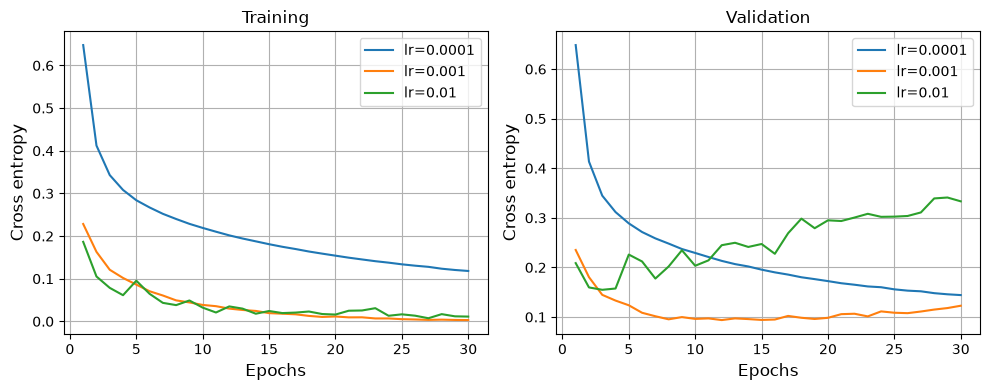

In [48]:
#RMSprop
fig, axes = plt.subplots(1, 2, figsize=(10,4))
for gamma, hist in history_lrr.items():
    epcoh=np.arange(1, len(hist["train"])+ 1)
    axes[0].plot(epcoh, hist['train'], label = f"lr={gamma:g}")
    axes[1].plot(epcoh, hist['val'], label = f"lr={gamma:g}")
axes[0].set_title('Training', fontsize=12)
axes[1].set_title('Validation', fontsize=12)
for ax in axes:
    ax.set_xlabel('Epochs', fontsize=12)
    ax.set_ylabel('Cross entropy', fontsize=12)
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()

Adam presterer generelt bedre. Orker ikke å teste mer med den.

Nå tester jeg ulike noder, aktiverings funksjoner i skjulte lag. Forsatt 10 noder i output og softmax i output. Bruker epoch = 30 og Adam med learning rate 0.001. 

In [51]:
activation_functions = ['relu', 'sigmoid', 'leaky_relu']
hidden_layers = [1, 2, 5]
nodes = [15, 50, 100]

results_arch = {}
histories_arch = {}
print(f"activation function| number of hidden layers| nodes| Min val loss| Best epoch| Accuracy after final epoch|")
for activation in activation_functions:
    for n_layers in hidden_layers:
        for node in nodes:
            model_arch = NeuralNetwork(layer_sizes=[784] + [node]*n_layers + [10], activations=[activation]*n_layers+ [ "softmax"], cost="cross_entropy", seed=2026)
            optimizer_arch = Adam(learning_rate=0.001)
            hist= train(model_arch, optimizer_arch, X=x_train, y=y_train_oh, epochs=30, batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)
            key = (activation, n_layers, node)
            histories_arch[key] = hist
            y_pred = model_arch.predict(x_val)
            val_accuracy = accuracy(y_val, y_pred)

            results_arch[key] = {
                "min_val_loss": float(min(hist['val'])),
                "best_epoch": int(np.argmin(hist['val'])+ 1),
                "final_val_loss": float(hist['val'][-1]),
                "final_val_accuracy": float(val_accuracy)
            }
            print(
            f"{activation} & {n_layers} & {node} & {min(hist['val']):.4f} & "
            f"{int(np.argmin(hist['val']) + 1)} & {val_accuracy:.4f} " + r"\\"
            )
        
            


activation function| number of hidden layers| nodes| Min val loss| Best epoch| Accuracy after final epoch|
relu & 1 & 15 & 0.1795 & 28 & 0.9478 \\
relu & 1 & 50 & 0.1025 & 18 & 0.9715 \\
relu & 1 & 100 & 0.0878 & 14 & 0.9771 \\
relu & 2 & 15 & 0.1833 & 27 & 0.9508 \\
relu & 2 & 50 & 0.1059 & 12 & 0.9701 \\
relu & 2 & 100 & 0.0908 & 7 & 0.9741 \\
relu & 5 & 15 & 0.1758 & 19 & 0.9494 \\
relu & 5 & 50 & 0.1222 & 12 & 0.9683 \\
relu & 5 & 100 & 0.0994 & 9 & 0.9750 \\
sigmoid & 1 & 15 & 0.1998 & 29 & 0.9426 \\
sigmoid & 1 & 50 & 0.1160 & 29 & 0.9670 \\
sigmoid & 1 & 100 & 0.0940 & 26 & 0.9739 \\
sigmoid & 2 & 15 & 0.2035 & 29 & 0.9395 \\
sigmoid & 2 & 50 & 0.1049 & 19 & 0.9681 \\
sigmoid & 2 & 100 & 0.0892 & 15 & 0.9768 \\
sigmoid & 5 & 15 & 0.3268 & 29 & 0.9153 \\
sigmoid & 5 & 50 & 0.1700 & 19 & 0.9551 \\
sigmoid & 5 & 100 & 0.1288 & 18 & 0.9682 \\
leaky_relu & 1 & 15 & 0.1810 & 28 & 0.9478 \\
leaky_relu & 1 & 50 & 0.1020 & 18 & 0.9711 \\
leaky_relu & 1 & 100 & 0.0884 & 14 & 0.9769 \\
lea

In [53]:
best_key = min(results_arch, key=lambda k: results_arch[k]['min_val_loss'])
print(f"Best (Activation function, number of hidden layers, number of nodes per layer):", best_key)
print(results_arch[best_key])

Best (Activation function, number of hidden layers, number of nodes per layer): ('leaky_relu', 2, 100)
{'min_val_loss': 0.08750886029210664, 'best_epoch': 6, 'final_val_loss': 0.1403165130795509, 'final_val_accuracy': 0.9777}


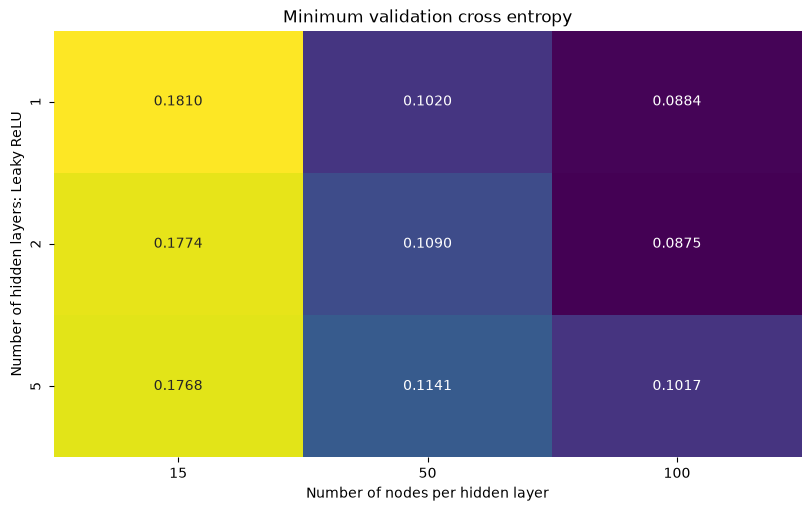

In [54]:
#Heat map for den beste komboen
#Tabell for det andre ...
activation = 'leaky_relu'
cross_entropy_grid = np.array([
    [results_arch[(activation, n_layers, node)]['min_val_loss']
                                           for node in nodes] 
                                           for n_layers in hidden_layers])
fig, ax = plt.subplots(figsize=(8,5), layout = "constrained")
plot_heatmap(values=cross_entropy_grid, x_labels=nodes, y_labels=hidden_layers, x_name='Number of nodes per hidden layer', 
             y_name= 'Number of hidden layers: Leaky ReLU', 
            title="Minimum validation cross entropy", fmt=".4f", ax=ax, cbar=False)

plt.show()

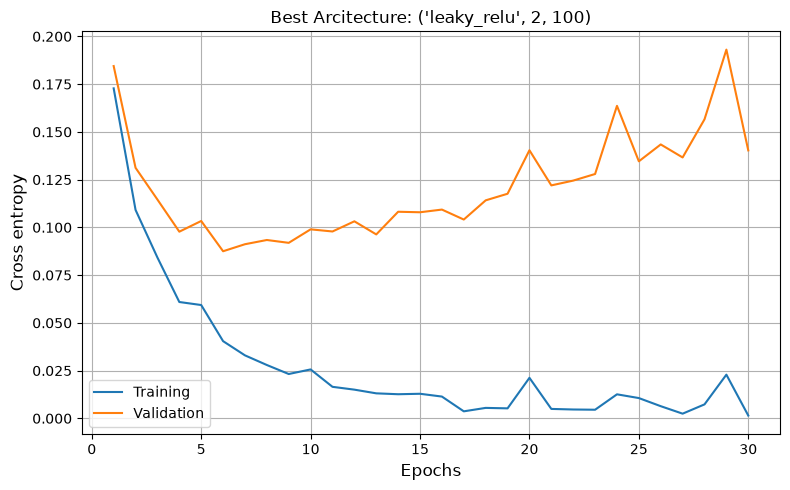

In [57]:
best_hist = histories_arch[best_key]
epochs = np.arange(1, len(best_hist['train']) + 1)
best_epoch = results_arch[best_key]['best_epoch']
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(epochs, best_hist['train'], label='Training')
ax.plot(epochs, best_hist['val'], label='Validation')
#ax.axvline(best_epoch, color="gray", linestyle="--", label=f"Minimum validation loss = {best_epoch}")
ax.set_xlabel('Epochs', fontsize=12)
ax.set_ylabel('Cross entropy', fontsize=12)
ax.set_title(f"Best Arcitecture: {best_key}")
ax.legend()
ax.grid()
plt.tight_layout()
plt.show()

Undersøker lambda

In [59]:
lambdas = [0.0, 1e-4, 1e-3, 1e-2]
results_l = {}
histories_l = {}
print(f"lambda| Min val loss| Best epoch| Accuracy after final epoch|")
for lam in lambdas:
    model_l = NeuralNetwork(layer_sizes=[784, 100, 100, 10], activations=["leaky_relu","leaky_relu","softmax"], 
                            cost="cross_entropy", l1=0.0, l2=lam, seed=2026)
    optimizer_l = Adam(learning_rate=0.001)
    hist_l = train_classification(model_l, optimizer_l, X=x_train, y=y_train_oh, epochs=30, batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)
    histories_l[lam] = hist_l
    y_pred = model_l.predict(x_val)
    val_accuracy_l = accuracy(y_val, y_pred)
    
    results_l[lam] = {
                    "min_val_loss": float(min(hist_l['val'])),
                    "best_epoch": int(np.argmin(hist_l['val'])+ 1),
                    "final_val_loss": float(hist_l['val'][-1]),
                    "final_val_accuracy": float(val_accuracy_l)
                }
    print(
    f"{lam:g} & {min(hist_l['val']):.4f} & "
    f"{np.argmin(hist_l['val']) + 1} & {val_accuracy_l:.4f} " + r"\\")
    
    

lambda| Min val loss| Best epoch| Accuracy after final epoch|
0 & 0.0875 & 6 & 0.9777 \\
0.0001 & 0.0870 & 7 & 0.9778 \\
0.001 & 0.0795 & 22 & 0.9728 \\
0.01 & 0.2112 & 24 & 0.9462 \\


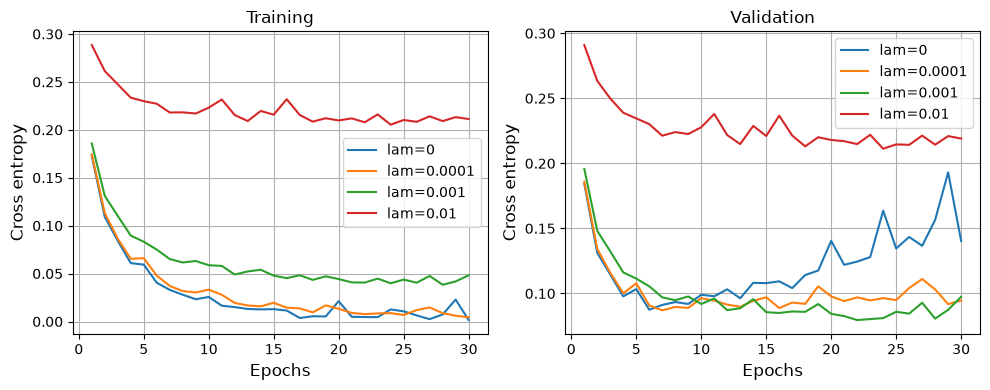

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))
for lam, hist_l in histories_l.items():
    epcoh=np.arange(1, len(hist_l["train"])+ 1)
    axes[0].plot(epcoh, hist_l['train'], label = f"lam={lam:g}")
    axes[1].plot(epcoh, hist_l['val'], label = f"lam={lam:g}")
axes[0].set_title('Training', fontsize=12)
axes[1].set_title('Validation', fontsize=12)
for ax in axes:
    ax.set_xlabel('Epochs', fontsize=12)
    ax.set_ylabel('Cross entropy', fontsize=12)
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()

In [60]:
best_lambda = min(results_l, key=lambda lam: results_l[lam]['min_val_loss'])
print(best_lambda, results_l[best_lambda])

0.001 {'min_val_loss': 0.07953917837634485, 'best_epoch': 22, 'final_val_loss': 0.0974757048834894, 'final_val_accuracy': 0.9728}


In [61]:
best_model = NeuralNetwork(layer_sizes=[784, 100, 100, 10], activations=["leaky_relu","leaky_relu","softmax"], 
                            cost="cross_entropy", l1=0.0, l2=0.001, seed=2026)
best_optimizer = Adam(learning_rate=0.001)
best_hist = train_classification(best_model, best_optimizer, X=x_train, y=y_train_oh, epochs=22, batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)

y_pred = best_model.predict(x_val)
print(f"Validation accuracy: {accuracy(y_val, y_pred):.4f}")
print(f"Validation cross entropy: {best_hist['val'][-1]:.4f}")


Validation accuracy: 0.9778
Validation cross entropy: 0.0795


Trene på test set med valgt model

In [62]:
y_pred_test = best_model.predict(x_test)
y_test_oh = one_hot(y_test)
test_ce = cross_entropy(best_model.forward(x_test), y_test_oh)
print(f"Test accuracy:{accuracy(y_test, y_pred_test):.4f}")
print(f"Cross entropy: {test_ce:.4f}")

Test accuracy:0.9777
Cross entropy: 0.0693


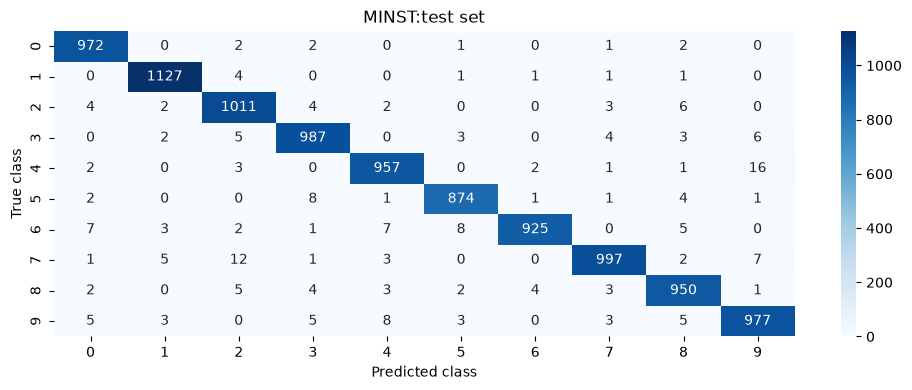

In [ ]:
fig, ax = plt.subplots(figsize=(10,4))
cm = np.zeros((10,10), dtype=int)
np.add.at(cm, (y_test, y_pred_test), 1)
confusion_matrix = plot_confusion(cm, class_labels=np.arange(10), title="MINST:test set", ax=ax)
plt.tight_layout()
plt.show()

In [ ]:
# Initialize the model (multinomial logistic regression with the saga solver)
model_logreg = LogisticRegression(solver="saga", max_iter=1000, random_state=2026)
# Train the model
model_logreg.fit(x_train, y_train)
# Make predictions on the test set
y_pred_logreg = model_logreg.predict(x_test)
# Calculate accuracy
accuracy_logreg = accuracy_score(y_test, y_pred_logreg)
print(f"Model Accuracy: {accuracy_logreg:.4f}")
test_ce_logreg = cross_entropy(model_logreg.predict_proba(x_test), y_test_oh)
print(f"Test cross-Entropy: {test_ce_logreg:.4f}")

Model Accuracy: 0.9253
Test cross-Entropy: 0.2784
